# Pipeline de análise de imagens de RX normal, pneumonia ou COVID19 visando emissão de laudos / diagnóstico automatizados a serem confirmados pelo profissional de medicina

### Rede Neural AlexNet (CNN-1)

In [1]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

dataset_path = "dataset"

pastas = ["NORMAL", "COVID", "PNEUMONIA"]

print("Pastas encontradas:")
print(pastas)

Pastas encontradas:
['NORMAL', 'COVID', 'PNEUMONIA']


In [2]:
import os
import numpy as np

d1 = "dataset"

normal_dir = d1 + "/NORMAL/"
covid_dir = d1 + "/COVID/"
pneumo_dir = d1 + "/PNEUMONIA/"

print("NORMAL:", len(os.listdir(normal_dir)))
print("COVID:", len(os.listdir(covid_dir)))
print("PNEUMONIA:", len(os.listdir(pneumo_dir)))

NORMAL: 1802
COVID: 1626
PNEUMONIA: 1800


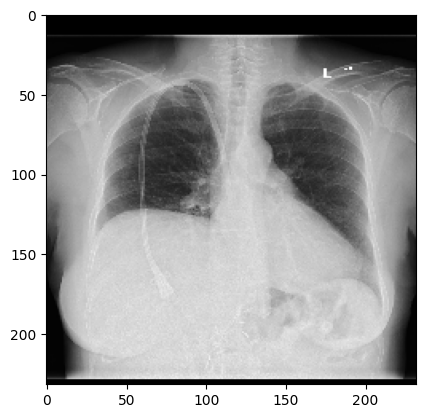

In [3]:
# Exemplo imagem normal
img = cv2.imread(normal_dir + "/NORMAL.png")
plt.imshow(img)
plt.show()

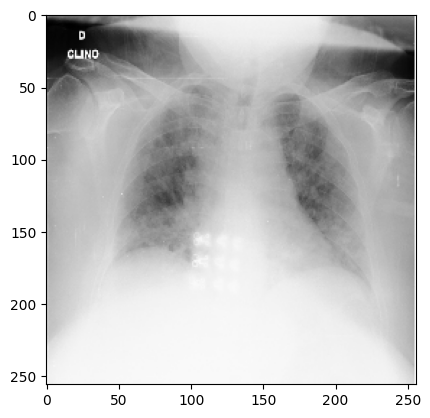

In [4]:
# Exemplo imagem covid
img = cv2.imread(covid_dir + "/COVID.png")
plt.imshow(img)
plt.show()

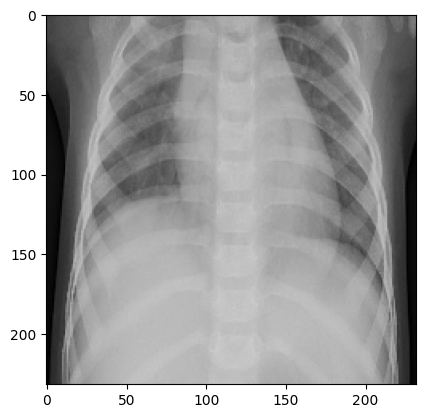

In [5]:
# Exemplo imagem pneumonia
img = cv2.imread(pneumo_dir + "/PNEUMONIA.png")
plt.imshow(img)
plt.show()

In [6]:
img.shape

(232, 232, 3)

In [7]:
# Carregando as imagens
def loadImages(path, urls, target):
  images = []
  labels = []
  for i in range(len(urls)):
    img_path = path + "/" + urls[i]
    img = cv2.imread(img_path)
    img = img / 255.0
    img = cv2.resize(img, (100, 100))
    images.append(img)
    labels.append(target)
  images = np.asarray(images)
  return images, labels

In [8]:
normal_path = normal_dir
normalUrl = sorted(os.listdir(normal_path))

normalImages, normalTargets = loadImages(
    normal_path,
    normalUrl,
    0
)

len(normalUrl), len(normalImages), len(normalTargets)

(1802, 1802, 1802)

In [9]:
covid_path = covid_dir
covidUrl = sorted(os.listdir(covid_path))

covidImages, covidTargets = loadImages(
    covid_path,
    covidUrl,
    1
)

len(covidUrl), len(covidImages), len(covidTargets)

(1626, 1626, 1626)

In [10]:
pneumo_path = pneumo_dir
pneumoUrl = sorted(os.listdir(pneumo_path))

pneumoImages, pneumoTargets = loadImages(
    pneumo_path,
    pneumoUrl,
    2
)

len(pneumoUrl), len(pneumoImages), len(pneumoTargets)

(1800, 1800, 1800)

In [11]:
normalImages.shape

(1802, 100, 100, 3)

In [12]:
covidImages.shape  

(1626, 100, 100, 3)

In [13]:
pneumoImages.shape

(1800, 100, 100, 3)

In [14]:
data = np.r_[
    normalImages,
    covidImages,
    pneumoImages
]

data.shape

(5228, 100, 100, 3)

In [15]:
targets = np.r_[
    normalTargets,
    covidTargets,
    pneumoTargets
]

targets.shape

(5228,)

In [16]:
print("Quantidade por classe:")
print("Normal:", np.sum(targets == 0))
print("Covid:", np.sum(targets == 1))
print("Pneumonia:", np.sum(targets == 2))

Quantidade por classe:
Normal: 1802
Covid: 1626
Pneumonia: 1800


In [17]:
print("Primeiros rótulos:", targets[:5])
print("Rótulos na transição Normal → Covid:", targets[1798:1807])
print("Últimos rótulos:", targets[-5:])

Primeiros rótulos: [0 0 0 0 0]
Rótulos na transição Normal → Covid: [0 0 0 0 1 1 1 1 1]
Últimos rótulos: [2 2 2 2 2]


In [18]:
from sklearn.model_selection import train_test_split
(x_train, x_test, y_train, y_test) = train_test_split(data, targets, test_size=0.20, stratify=targets, random_state=42)

In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Input(shape=(100, 100, 3)),

    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),

    Conv2D(16, 3, activation="relu"),
    MaxPooling2D(),

    Conv2D(16, 3, activation="relu"),
    MaxPooling2D(),

    Flatten(),

    Dense(512, activation="relu"),
    Dense(256, activation="relu"),

    Dense(3, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       819,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 959,651 (3.66 MB)

 Trainable params: 959,651 (3.66 MB)

 Non-trainable params: 0 (0.00 B)

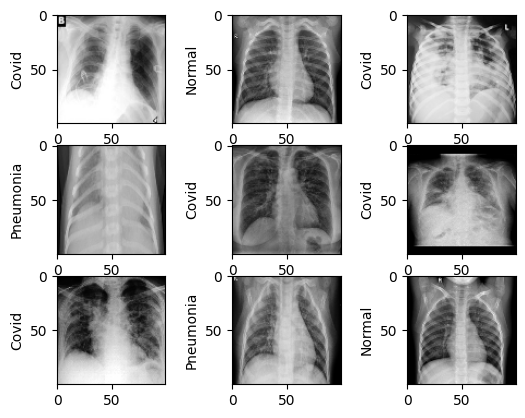

In [20]:
# Cria lista de rótulos para as imagens
category_dict = {
    0: "Normal",
    1: "Covid",
    2: "Pneumonia"
}

# Visualizando algumas imagens do dataset
plt.figure()
for i in range(9):
  # cria um grafico de 3 x 3
  plt.subplot(3,3,i+1)
  # mostra a imagem
  plt.imshow(x_train[i])
  # mostra o rotulo
  plt.ylabel(category_dict[y_train[i]])
plt.show()

In [21]:
# Definindo os hiperparametros
batch_size   = 32
input_shape = (100, 100, 3)
random_state = 42
alpha        = 1e-5
epoch        = 5

In [22]:
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau

model_name = "final_covid.keras"

checkpoint = ModelCheckpoint(
    filepath=model_name,
    monitor="val_loss",
    verbose=1,
    save_best_only=True,
    mode="min"
)

lr_reduce = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    min_delta=1e-5,
    patience=5,
    verbose=1
)

callbacks = [checkpoint, lr_reduce]

In [23]:
# Treinando o modelo
opt = tf.keras.optimizers.Adam(learning_rate=0.0001)
model.compile(loss='sparse_categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epoch,
    validation_data=(x_test, y_test),
    callbacks=callbacks
)

best_model = tf.keras.models.load_model("final_covid.keras")

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7551 - loss: 0.6599
Epoch 1: val_loss improved from None to 0.41388, saving model to final_covid.keras

Epoch 1: finished saving model to final_covid.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.7551 - loss: 0.6599 - val_accuracy: 0.8021 - val_loss: 0.4139 - learning_rate: 1.0000e-04
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8914 - loss: 0.3072
Epoch 2: val_loss improved from 0.41388 to 0.24169, saving model to final_covid.keras

Epoch 2: finished saving model to final_covid.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.8914 - loss: 0.3072 - val_accuracy: 0.9149 - val_loss: 0.2417 - learning_rate: 1.0000e-04
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9096 - loss: 0.2451
Epoch 3: val_loss improved from 0.24169 to 0.19186, saving model to final_covid.keras

Epoch 3: finished saving model to final_covid.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms

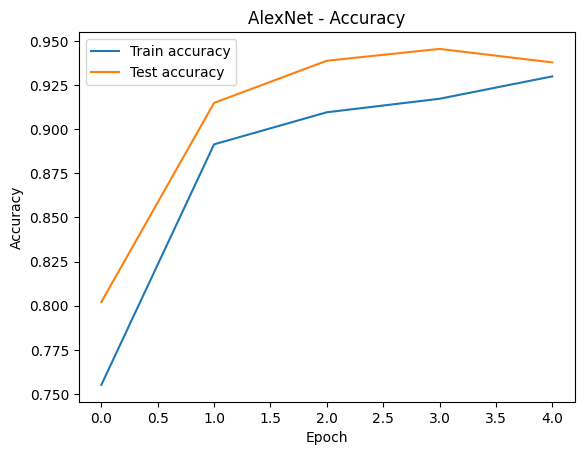

In [24]:
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("AlexNet - Accuracy")
plt.legend()
plt.show()

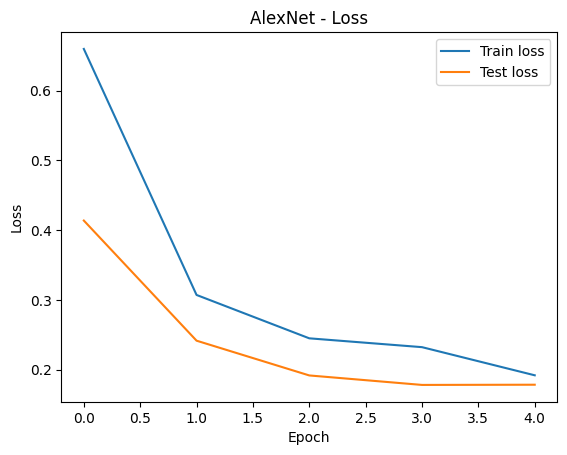

In [25]:
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet - Loss")
plt.legend()
plt.show()

In [26]:
test_loss, test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.1783
Test Accuracy: 0.9455


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
RELATÓRIO DE CLASSIFICAÇÃO — ALEXNET
Ordem: NORMAL, COVID, PNEUMONIA
              precision    recall  f1-score   support

      Normal     0.9350    0.9557    0.9452       361
       Covid     0.9748    0.9508    0.9626       325
   Pneumonia     0.9306    0.9306    0.9306       360

    accuracy                         0.9455      1046
   macro avg     0.9468    0.9457    0.9461      1046
weighted avg     0.9458    0.9455    0.9456      1046

Acurácia:          0.9455
Precisão macro:    0.9468
Recall macro:      0.9457
F1-score macro:    0.9461
Precisão weighted: 0.9458
Recall weighted:   0.9455
F1 weighted:       0.9456
Cohen Kappa:       0.9181

Matriz de confusão:
[[345   3  13]
 [  4 309  12]
 [ 20   5 335]]

Métricas por classe:
Normal: Recall = 0.9557 | Especificidade = 0.9650
Covid: Recall = 0.9508 | Especificidade = 0.9889
Pneumonia: Recall = 0.9306 | Especificidade = 0.9636


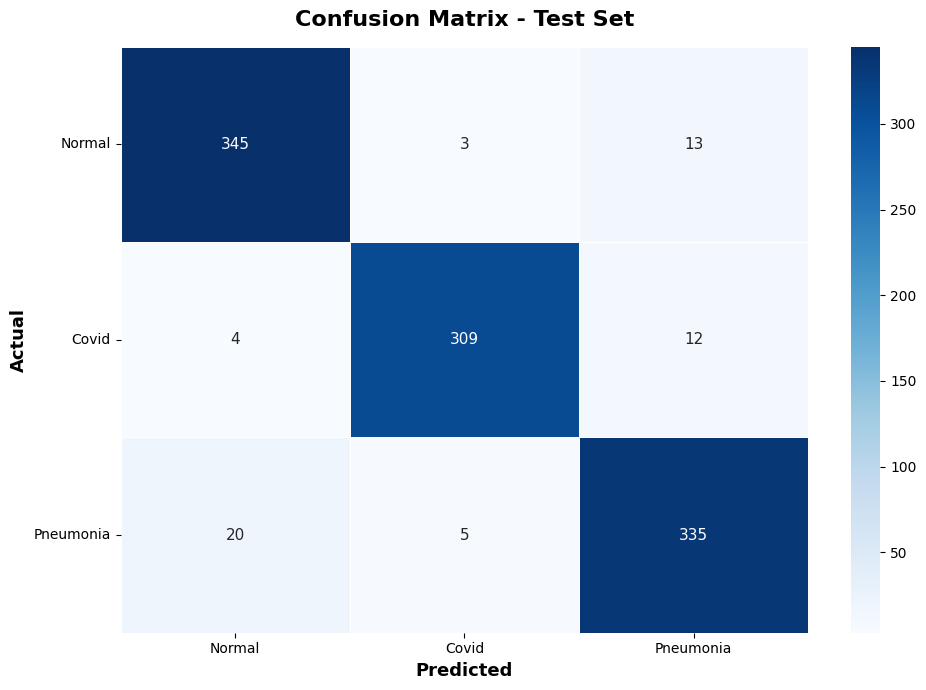

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

# Ordem oficial das classes
class_ids = [0, 1, 2]
class_names = ["Normal", "Covid", "Pneumonia"]

# Probabilidades previstas pelo modelo
y_prob = best_model.predict(x_test, verbose=1)

# Classe com maior probabilidade
y_pred = np.argmax(y_prob, axis=1)

# Classes verdadeiras
y_true = np.asarray(y_test).astype(int)

# Matriz com ordem fixa:
# 0 = Normal, 1 = Covid, 2 = Pneumonia
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids
)

print("=" * 65)
print("RELATÓRIO DE CLASSIFICAÇÃO — ALEXNET")
print("Ordem: NORMAL, COVID, PNEUMONIA")
print("=" * 65)

print(
    classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

accuracy = accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="weighted",
    zero_division=0
)

kappa = cohen_kappa_score(y_true, y_pred)

print(f"Acurácia:          {accuracy:.4f}")
print(f"Precisão macro:    {precision_macro:.4f}")
print(f"Recall macro:      {recall_macro:.4f}")
print(f"F1-score macro:    {f1_macro:.4f}")
print(f"Precisão weighted: {precision_weighted:.4f}")
print(f"Recall weighted:   {recall_weighted:.4f}")
print(f"F1 weighted:       {f1_weighted:.4f}")
print(f"Cohen Kappa:       {kappa:.4f}")

print("\nMatriz de confusão:")
print(cm)



print("\nMétricas por classe:")

total = cm.sum()

for i, class_name in enumerate(class_names):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = total - tp - fn - fp

    recall_classe = tp / (tp + fn) if (tp + fn) > 0 else 0
    especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0

    print(
        f"{class_name}: "
        f"Recall = {recall_classe:.4f} | "
        f"Especificidade = {especificidade:.4f}"
    )



plt.figure(figsize=(10, 7))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    annot_kws={"size": 11}
)

ax.set_title(
    "Confusion Matrix - Test Set",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Predicted",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Actual",
    fontsize=13,
    fontweight="bold"
)

plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
os.makedirs("models", exist_ok=True)

In [29]:
model.save('models/covid_detection_model.keras')

In [30]:
loaded_model = tf.keras.models.load_model("models/covid_detection_model.keras")

In [31]:
from PIL import Image
import numpy as np

test_image = Image.open(covid_dir + "COVID.png")

test_image = test_image.resize((100, 100))

if test_image.mode != "RGB":
    test_image = test_image.convert("RGB")

test_image = np.array(test_image, dtype=np.float32)

# Mesma normalização usada no treinamento
test_image = test_image / 255.0

test_image = np.expand_dims(test_image, axis=0)

result = model.predict(test_image, verbose=0)

classe = np.argmax(result[0])

print("Probabilidades:", result[0])
print("Classe prevista:", category_dict[classe])

Probabilidades: [6.8761765e-05 9.9909353e-01 8.3771290e-04]
Classe prevista: Covid


In [32]:
result[0]

array([6.8761765e-05, 9.9909353e-01, 8.3771290e-04], dtype=float32)

In [33]:
classe = np.argmax(result[0])

if classe == 0:
    print("Normal")
elif classe == 1:
    print("COVID")
elif classe == 2:
    print("PNEUMONIA")

COVID


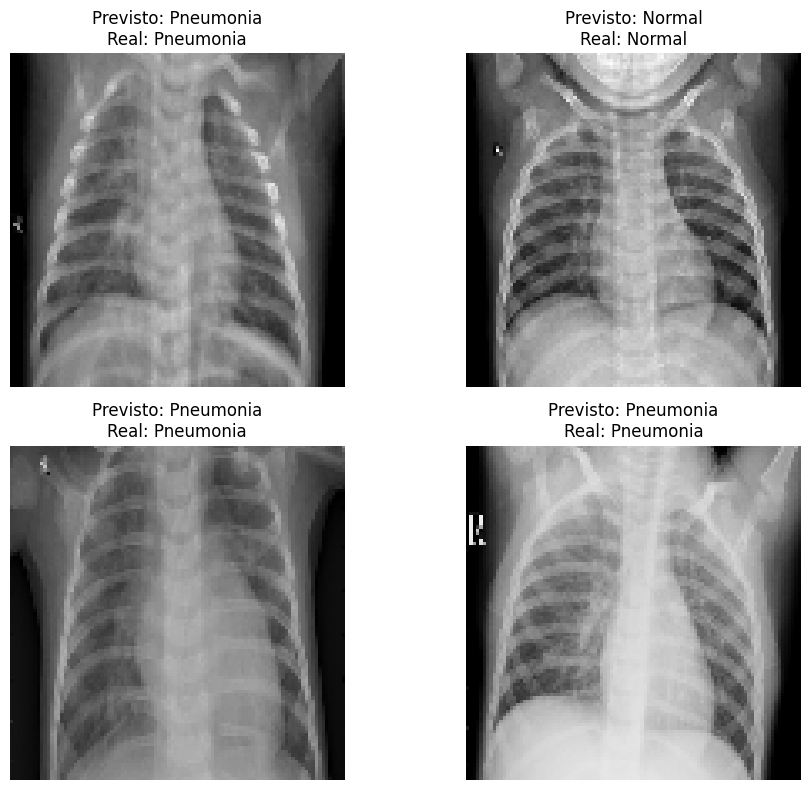

Rótulos previstos: [np.int64(2), np.int64(0), np.int64(2), np.int64(2)]


In [34]:
# Lista de rótulos preditos
pred_list = []

# Realiza a previsão apenas uma vez para as 4 imagens
pred = np.argmax(
    loaded_model.predict(x_test[:4], verbose=0),
    axis=1
)

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)

    # Exibe a imagem
    plt.imshow(x_test[i])

    # Obtém os nomes das classes
    classe_prevista = category_dict[pred[i]]
    classe_real = category_dict[y_test[i]]

    # Armazena apenas o rótulo previsto da imagem atual
    pred_list.append(pred[i])

    # Mostra previsão e classe real
    plt.title(
        f"Previsto: {classe_prevista}\n"
        f"Real: {classe_real}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("Rótulos previstos:", pred_list)